<a href="https://colab.research.google.com/github/fizzahsohail429/Underwater-Image-Enhanncement-and-Restoration/blob/main/deeplabcode.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Image enhancement completed
DeepLab model loaded successfully from TensorFlow Hub
tf.Tensor(
[[[ 2.  2.  2. ...  3.  3.  3.]
  [ 2.  2.  2. ...  3.  3.  3.]
  [ 2.  2.  2. ...  3.  3.  3.]
  ...
  [ 1.  1.  1. ... 14. 14. 14.]
  [ 1.  1.  1. ... 14. 14. 14.]
  [ 1.  1.  1. ... 14. 14. 14.]]], shape=(1, 512, 512), dtype=float32) !!!!!!!!!!!!!!!!!!!!!
Segmentation completed successfully


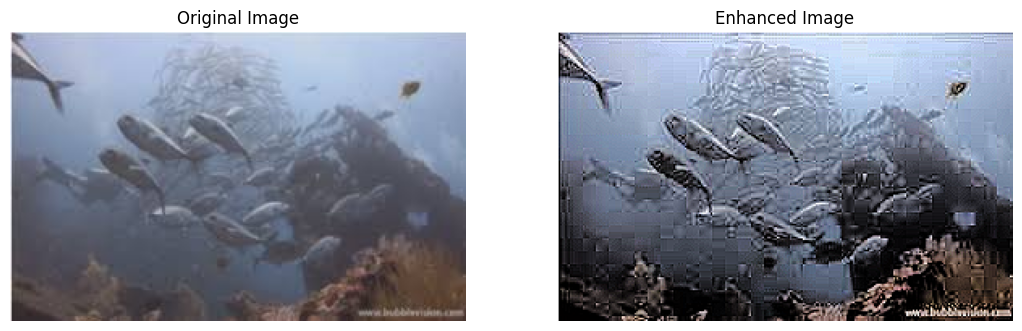

In [4]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_hub as hub

# Set TensorFlow log level to suppress unnecessary warnings
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

# Load the image from the given directory
image_path = "/content/sample_data/underwater_image_sampl1.jpg"  # Replace with your image path
original_image = cv2.imread(image_path)
if original_image is None:
    raise FileNotFoundError(f"Image not found at {image_path}")

# Convert to RGB for matplotlib
original_image_rgb = cv2.cvtColor(original_image, cv2.COLOR_BGR2RGB)

# Step 1: Enhance detected objects using basic image processing techniques
# Convert to HSV to manipulate brightness/contrast
hsv_image = cv2.cvtColor(original_image, cv2.COLOR_BGR2HSV)
h, s, v = cv2.split(hsv_image)

# Apply histogram equalization to the V channel for brightness/contrast enhancement
v_enhanced = cv2.equalizeHist(v)

# Merge back and convert to BGR
hsv_enhanced = cv2.merge([h, s, v_enhanced])
enhanced_image = cv2.cvtColor(hsv_enhanced, cv2.COLOR_HSV2BGR)

# Optional: Apply a sharpening kernel to the enhanced image
sharpen_kernel = np.array([[0, -1, 0],
                           [-1, 5, -1],
                           [0, -1, 0]])
sharpened_image = cv2.filter2D(enhanced_image, -1, sharpen_kernel)
print("Image enhancement completed")

# Step 2: Apply DeepLab model for semantic segmentation on the enhanced image
# Load a pre-trained DeepLab model from TensorFlow Hub
try:
    model = hub.KerasLayer('https://www.kaggle.com/models/google/deeplab-edgetpu/TensorFlow2/default-argmax-m/1', trainable=False)
    print("DeepLab model loaded successfully from TensorFlow Hub")
except Exception as e:
    print(f"Error loading DeepLab model: {e}")
    exit()

# Preprocess the enhanced image for the DeepLab model
# Convert enhanced image to RGB (DeepLab model expects RGB format)
enhanced_image_rgb = cv2.cvtColor(sharpened_image, cv2.COLOR_BGR2RGB)

# Resize the image for the model to 512x512 as required by the model
input_image = cv2.resize(enhanced_image_rgb, (512, 512))  # Resize to 512x512

# Normalize the image
input_image = np.expand_dims(input_image / 255.0, axis=0)

# Run the DeepLab model to get the segmentation map
try:
    # Convert the input image to a tensor
    input_tensor = tf.convert_to_tensor(input_image, dtype=tf.float32)
    # Run the model to get the segmentation result
    segmentation_map = model(input_tensor)
    print(segmentation_map,'!!!!!!!!!!!!!!!!!!!!!')
    if isinstance(segmentation_map, dict):
        segmentation_map = segmentation_map['semantic'].numpy()[0]
    print("Segmentation completed successfully")
except Exception as e:
    print(f"Error during segmentation: {e}")
    exit()

# Resize the segmentation map back to original image dimensions
# segmentation_map_resized = cv2.resize(segmentation_map.astype(np.uint8), (original_image.shape[1], original_image.shape[0]))
# segmentation_map_resized = cv2.resize(segmentation_map.astype(np.uint8), (original_image.shape[1], original_image.shape[0]))

# # Define a color map to visualize the segmentation classes
# def colorize_segmentation(segmentation_map):
#     # Define a set of colors for each class index
#     colormap = np.array([
#         [0, 0, 0],       # Class 0 - Background
#         [128, 0, 0],     # Class 1 - First class (e.g., road)
#         [0, 128, 0],     # Class 2 - Second class (e.g., water)
#         [128, 128, 0],   # Class 3 - Third class
#         [0, 0, 128],     # Class 4 - Fourth class (e.g., sky)
#         [128, 0, 128],   # Class 5
#         [0, 128, 128],   # Class 6
#         [128, 128, 128], # Class 7
#         [64, 0, 0],      # Class 8
#         [192, 0, 0],     # Class 9
#         [64, 128, 0],    # Class 10
#         [192, 128, 0],   # Class 11
#         [64, 0, 128],    # Class 12
#         [192, 0, 128],   # Class 13
#         [64, 128, 128],  # Class 14 - Your class 14
#         [192, 128, 128]  # Class 15 - Example additional class
#     ])

#     # Clip the segmentation map to the range of defined classes
#     segmentation_map = np.clip(segmentation_map, 0, len(colormap) - 1)
#     return colormap[segmentation_map]

# # Colorize the segmentation map for visualization
# colored_segmentation_map = colorize_segmentation(segmentation_map_resized)
# Step 3: Display the original image, enhanced image, and DeepLab segmented image
plt.figure(figsize=(20, 10))

# Show Original Image
plt.subplot(1, 3, 1)
plt.imshow(original_image_rgb)
plt.title('Original Image')
plt.axis('off')

# Show Enhanced Image
plt.subplot(1, 3, 2)
plt.imshow(enhanced_image_rgb)
plt.title('Enhanced Image')
plt.axis('off')

# Show DeepLab Segmentation Result
# plt.subplot(1, 3, 3)
# # Use a color map for better visualization of segmentation results
# plt.imshow(segmentation_map_resized, cmap='jet', alpha=0.6)
# plt.title('DeepLab Segmented Image')
# plt.axis('off')

# Display all images
plt.show()